# Lab 9- Deep Learning Model

This lab is meant to get you started in using Keras to design Deep Neural Networks. The goal here is to simply repeat your previous lab, but with DNNs.

Lecture 21 is your template: it reads the same data, builds, compiles and trains a network, plots its learning curves, and makes a ROC curve. Copy its cells and change the numbers.

Let's start with reading the data, like before. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, as in Lab 8. You will need both in Exercise 2.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

filename="../Lab.7/SUSY-small.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]

df = pd.read_csv(filename, dtype='float64', names=VarNames)

Now let's define the samples. DNNs take long to train, so to start we use only the first 500,000 of the 5 million events for training. Once you get everything working, make the final version of your plots with more.

We keep **three** samples, because they do different jobs:

* **training**: what `fit` learns from;
* **validation**: what you watch while you work (pass it to `fit` as `validation_data`), and what you use to choose between models;
* **test**: used only at the end, to report the performance of the models you chose.

Keras works on NumPy arrays, so after doing all of the nice manipulation that pandas enables, we convert the DataFrames to NumPy arrays.

In [14]:
N_Train=50000
N_Val=5000
N_Test=5000

Train_Sample=df[:N_Train]
Val_Sample=df[N_Train:N_Train+N_Val]
Test_Sample=df[N_Train+N_Val:N_Train+N_Val+N_Test]

X_Train=np.array(Train_Sample[VarNames[1:]])
y_Train=np.array(Train_Sample["signal"])

X_Val=np.array(Val_Sample[VarNames[1:]])
y_Val=np.array(Val_Sample["signal"])

X_Test=np.array(Test_Sample[VarNames[1:]])
y_Test=np.array(Test_Sample["signal"])

print(X_Train.shape, X_Val.shape, X_Test.shape)

(50000, 18) (5000, 18) (5000, 18)


## Exercise 1

You will need to create several models and make sure they are properly trained. Write a function that takes this history and plots the values versus epoch. For every model that you train in the remainder of this lab, assess:

* Has your model's performance plateaued? If not train for more epochs. 
* Compare the performance on the training and validation samples. Are you over training?

In [9]:
def plot_history(history):

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(history.history["accuracy"], label="Training Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

In [10]:
%pip install tensorflow
import tensorflow as tf
print(tf.__version__)

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
2.20.0


In [4]:
from tensorflow import keras
from tensorflow.keras import layers

model1 = keras.Sequential([
    layers.Input(shape=(18,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model1.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,329 (13.00 KB)

 Trainable params: 3,329 (13.00 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history1 = model1.fit(
    X_Train,
    y_Train,
    epochs=20,
    batch_size=256,
    validation_data=(X_Val, y_Val)
)

Epoch 1/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6967 - loss: 0.5743 - val_accuracy: 0.7796 - val_loss: 0.4619
Epoch 2/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 733us/step - accuracy: 0.7881 - loss: 0.4569 - val_accuracy: 0.7850 - val_loss: 0.4515
Epoch 3/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 748us/step - accuracy: 0.7929 - loss: 0.4455 - val_accuracy: 0.7800 - val_loss: 0.4473
Epoch 4/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 805us/step - accuracy: 0.7940 - loss: 0.4463 - val_accuracy: 0.7818 - val_loss: 0.4438
Epoch 5/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 710us/step - accuracy: 0.7972 - loss: 0.4377 - val_accuracy: 0.7846 - val_loss: 0.4426
Epoch 6/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 687us/step - accuracy: 0.7974 - loss: 0.4368 - val_accuracy: 0.7850 - val_loss: 0.4432
Epoch 7/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 699us/step - accuracy: 0.7994 - loss: 0.4349 - val_accuracy: 0.7856 - val_loss: 0.4405
Epoch 8/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 742us/step - accuracy: 0.7966 - loss: 0.4381 - va

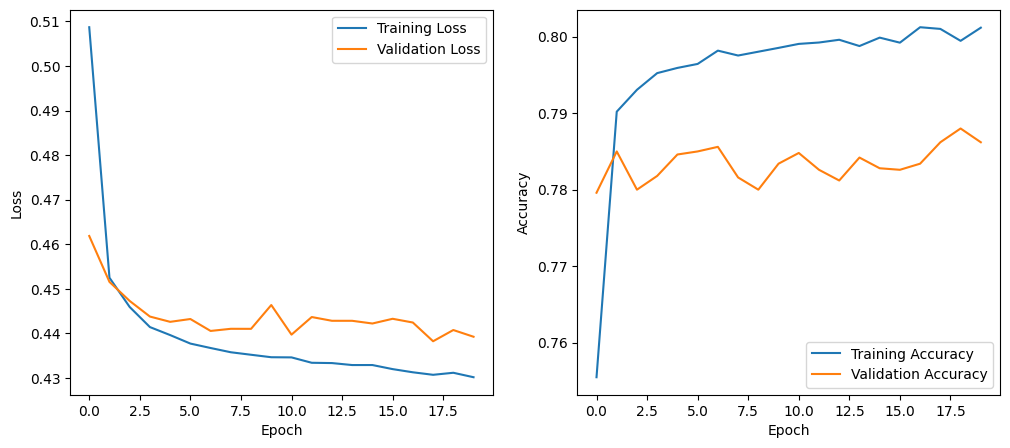

In [12]:
plot_history(history1)

## Exercise 2

Following the original paper (see Lab 7), make a comparison of the performance (using ROC curves and AUC) between models trained with the raw quantities (`RawNames`), the derived features (`FeatureNames`), and both. Note that the first layer's input shape changes with the number of inputs.

In [17]:
X_Train_Raw = X_Train[:, [VarNames.index(name) - 1 for name in RawNames]]
X_Val_Raw = X_Val[:, [VarNames.index(name) - 1 for name in RawNames]]
X_Test_Raw = X_Test[:, [VarNames.index(name) - 1 for name in RawNames]]

X_Train_Features = X_Train[:, [VarNames.index(name) - 1 for name in FeatureNames]]
X_Val_Features = X_Val[:, [VarNames.index(name) - 1 for name in FeatureNames]]
X_Test_Features = X_Test[:, [VarNames.index(name) - 1 for name in FeatureNames]]

X_Train_All = X_Train
X_Val_All = X_Val
X_Test_All = X_Test

print(X_Train_Raw.shape)
print(X_Train_Features.shape)
print(X_Train_All.shape)

(50000, 8)
(50000, 10)
(50000, 18)


In [18]:
def create_model(input_size):
    model = keras.Sequential([
        layers.Input(shape=(input_size,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

model_raw = create_model(8)
model_features = create_model(10)
model_all = create_model(18)

Epoch 1/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 795us/step - accuracy: 0.7894 - loss: 0.4457 - val_accuracy: 0.7806 - val_loss: 0.4507
Epoch 2/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 693us/step - accuracy: 0.7915 - loss: 0.4429 - val_accuracy: 0.7828 - val_loss: 0.4547
Epoch 3/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 726us/step - accuracy: 0.7921 - loss: 0.4414 - val_accuracy: 0.7832 - val_loss: 0.4499
Epoch 4/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 677us/step - accuracy: 0.7916 - loss: 0.4443 - val_accuracy: 0.7858 - val_loss: 0.4498
Epoch 5/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 677us/step - accuracy: 0.7947 - loss: 0.4424 - val_accuracy: 0.7822 - val_loss: 0.4496
Epoch 6/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 664us/step - accuracy: 0.7962 - loss: 0.4381 - val_accuracy: 0.7818 - val_loss: 0.4552
Epoch 7/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 663us/step - accuracy: 0.7938 - loss: 0.4407 - val_accuracy: 0.7824 - val_loss: 0.4520
Epoch 8/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 676us/step - accuracy: 0.7947 - loss: 0.4409 - 

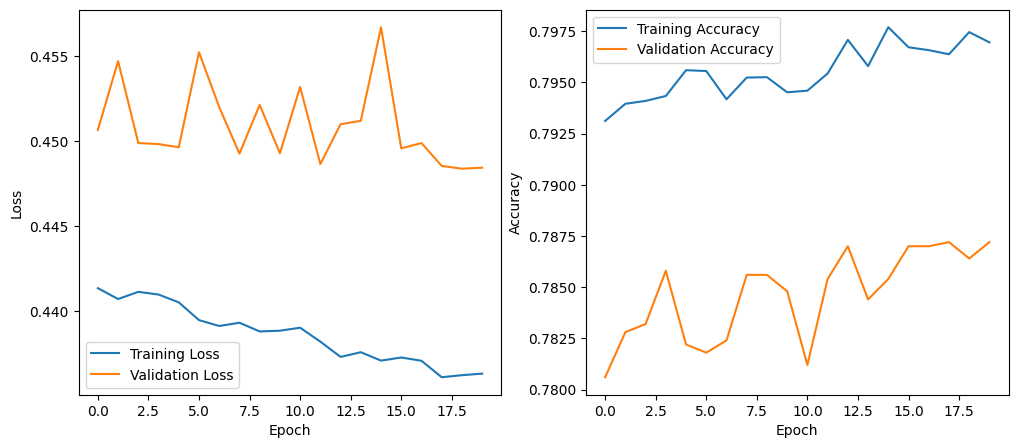

In [21]:
history_raw = model_raw.fit(
    X_Train_Raw,
    y_Train,
    epochs=20,
    batch_size=256,
    validation_data=(X_Val_Raw, y_Val)
)

plot_history(history_raw)

Epoch 1/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6878 - loss: 0.6015 - val_accuracy: 0.7714 - val_loss: 0.4824
Epoch 2/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 727us/step - accuracy: 0.7827 - loss: 0.4684 - val_accuracy: 0.7742 - val_loss: 0.4677
Epoch 3/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 718us/step - accuracy: 0.7860 - loss: 0.4587 - val_accuracy: 0.7774 - val_loss: 0.4613
Epoch 4/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 703us/step - accuracy: 0.7861 - loss: 0.4573 - val_accuracy: 0.7808 - val_loss: 0.4596
Epoch 5/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 690us/step - accuracy: 0.7861 - loss: 0.4574 - val_accuracy: 0.7786 - val_loss: 0.4626
Epoch 6/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 689us/step - accuracy: 0.7843 - loss: 0.4573 - val_accuracy: 0.7812 - val_loss: 0.4582
Epoch 7/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 686us/step - accuracy: 0.7909 - loss: 0.4511 - val_accuracy: 0.7804 - val_loss: 0.4574
Epoch 8/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 689us/step - accuracy: 0.7891 - loss: 0.4514 - va

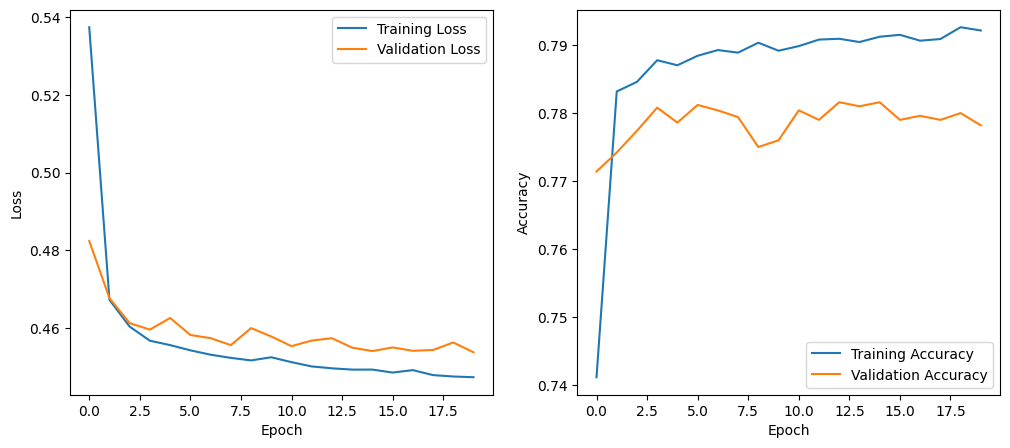

In [22]:
history_features = model_features.fit(
    X_Train_Features,
    y_Train,
    epochs=20,
    batch_size=256,
    validation_data=(X_Val_Features, y_Val)
)

plot_history(history_features)

Epoch 1/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6946 - loss: 0.5726 - val_accuracy: 0.7822 - val_loss: 0.4584
Epoch 2/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 709us/step - accuracy: 0.7920 - loss: 0.4504 - val_accuracy: 0.7804 - val_loss: 0.4519
Epoch 3/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 707us/step - accuracy: 0.7931 - loss: 0.4469 - val_accuracy: 0.7802 - val_loss: 0.4479
Epoch 4/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 701us/step - accuracy: 0.7949 - loss: 0.4435 - val_accuracy: 0.7890 - val_loss: 0.4443
Epoch 5/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 703us/step - accuracy: 0.7945 - loss: 0.4413 - val_accuracy: 0.7842 - val_loss: 0.4507
Epoch 6/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 722us/step - accuracy: 0.7972 - loss: 0.4402 - val_accuracy: 0.7868 - val_loss: 0.4427
Epoch 7/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 692us/step - accuracy: 0.7978 - loss: 0.4349 - val_accuracy: 0.7838 - val_loss: 0.4424
Epoch 8/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 693us/step - accuracy: 0.8001 - loss: 0.4326 - va

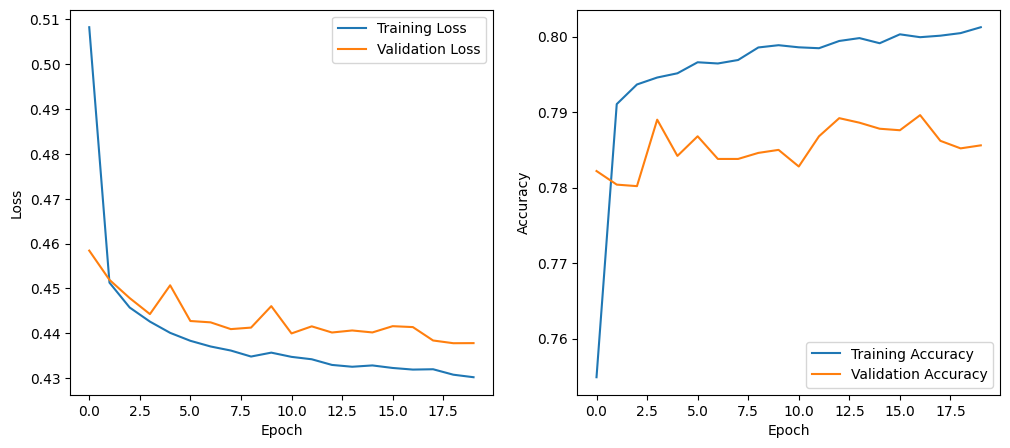

In [23]:
history_all = model_all.fit(
    X_Train_All,
    y_Train,
    epochs=20,
    batch_size=256,
    validation_data=(X_Val_All, y_Val)
)

plot_history(history_all)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 382us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 361us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 357us/step


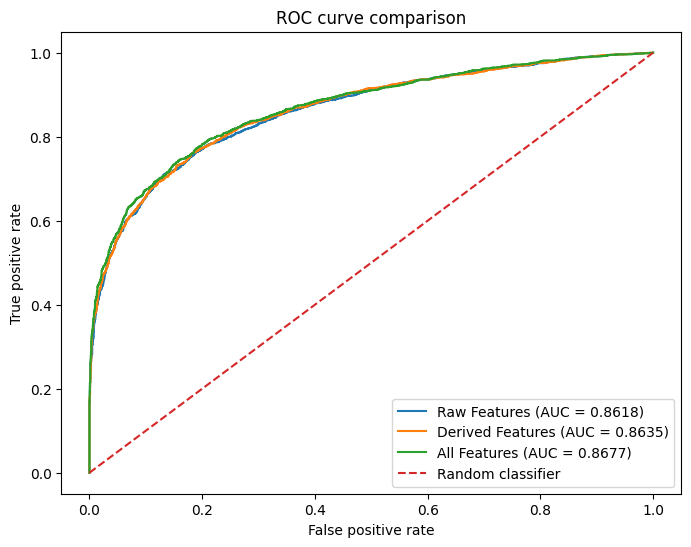

Raw features AUC: 0.861810455626245
Derived features AUC: 0.8634973652078914
All features AUC: 0.8677448428764218


In [24]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_pred_raw = model_raw.predict(X_Test_Raw).ravel()
y_pred_features = model_features.predict(X_Test_Features).ravel()
y_pred_all = model_all.predict(X_Test_All).ravel()

fpr_raw, tpr_raw, _ = roc_curve(y_Test, y_pred_raw)
fpr_features, tpr_features, _ = roc_curve(y_Test, y_pred_features)
fpr_all, tpr_all, _ = roc_curve(y_Test, y_pred_all)

auc_raw = roc_auc_score(y_Test, y_pred_raw)
auc_features = roc_auc_score(y_Test, y_pred_features)
auc_all = roc_auc_score(y_Test, y_pred_all)

plt.figure(figsize=(8, 6))
plt.plot(fpr_raw, tpr_raw, label=f"Raw Features (AUC = {auc_raw:.4f})")
plt.plot(fpr_features, tpr_features, label=f"Derived Features (AUC = {auc_features:.4f})")
plt.plot(fpr_all, tpr_all, label=f"All Features (AUC = {auc_all:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve comparison")
plt.legend()
plt.show()

print("Raw features AUC:", auc_raw)
print("Derived features AUC:", auc_features)
print("All features AUC:", auc_all)

## Exercise 3

Design and implement at least 3 different DNN models. Train them and compare performance. You may try different architectures, loss functions, and optimizers to see if there is an effect.

In [25]:
def create_model_1():
    model = keras.Sequential([
        layers.Input(shape=(18,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

def create_model_2():
    model = keras.Sequential([
        layers.Input(shape=(18,)),
        layers.Dense(128, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer="rmsprop",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

def create_model_3():
    model = keras.Sequential([
        layers.Input(shape=(18,)),
        layers.Dense(64, activation="tanh"),
        layers.Dense(64, activation="tanh"),
        layers.Dense(32, activation="tanh"),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

Epoch 1/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 922us/step - accuracy: 0.6135 - loss: 0.6741 - val_accuracy: 0.7750 - val_loss: 0.5012
Epoch 2/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 617us/step - accuracy: 0.7859 - loss: 0.4851 - val_accuracy: 0.7798 - val_loss: 0.4628
Epoch 3/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 616us/step - accuracy: 0.7905 - loss: 0.4556 - val_accuracy: 0.7798 - val_loss: 0.4567
Epoch 4/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 633us/step - accuracy: 0.7907 - loss: 0.4526 - val_accuracy: 0.7826 - val_loss: 0.4542
Epoch 5/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 648us/step - accuracy: 0.7942 - loss: 0.4470 - val_accuracy: 0.7818 - val_loss: 0.4525
Epoch 6/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 612us/step - accuracy: 0.7945 - loss: 0.4439 - val_accuracy: 0.7844 - val_loss: 0.4491
Epoch 7/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 615us/step - accuracy: 0.7945 - loss: 0.4448 - val_accuracy: 0.7846 - val_loss: 0.4480
Epoch 8/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 606us/step - accuracy: 0.7954 - loss: 0.4426 - 

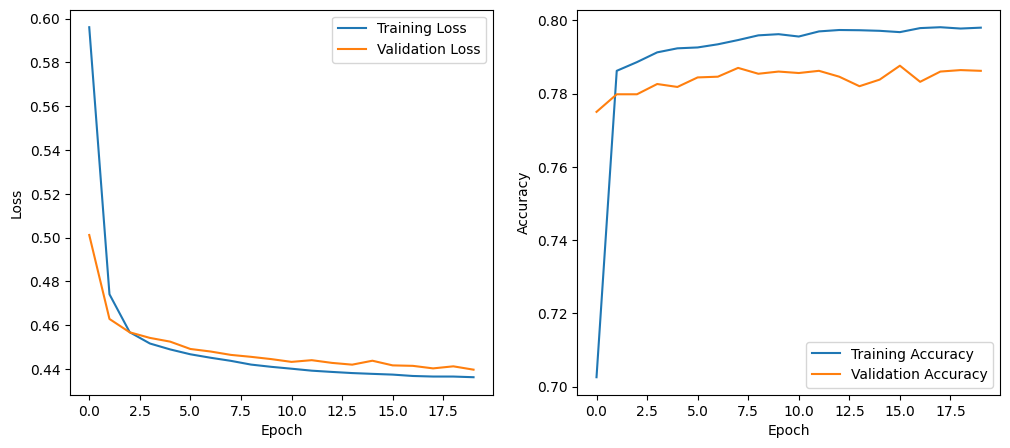

In [26]:
dnn1 = create_model_1()
dnn2 = create_model_2()
dnn3 = create_model_3()

history_dnn1 = dnn1.fit(
    X_Train_All,
    y_Train,
    epochs=20,
    batch_size=256,
    validation_data=(X_Val_All, y_Val)
)

plot_history(history_dnn1)

Epoch 1/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7432 - loss: 0.5223 - val_accuracy: 0.7834 - val_loss: 0.4555
Epoch 2/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7916 - loss: 0.4474 - val_accuracy: 0.7868 - val_loss: 0.4540
Epoch 3/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7944 - loss: 0.4424 - val_accuracy: 0.7852 - val_loss: 0.4484
Epoch 4/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7972 - loss: 0.4389 - val_accuracy: 0.7888 - val_loss: 0.4447
Epoch 5/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7952 - loss: 0.4399 - val_accuracy: 0.7824 - val_loss: 0.4419
Epoch 6/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7993 - loss: 0.4343 - val_accuracy: 0.7786 - val_loss: 0.4618
Epoch 7/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7997 - loss: 0.4324 - val_accuracy: 0.7840 - val_loss: 0.4446
Epoch 8/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7972 - loss: 0.4398 - val_accuracy: 0.

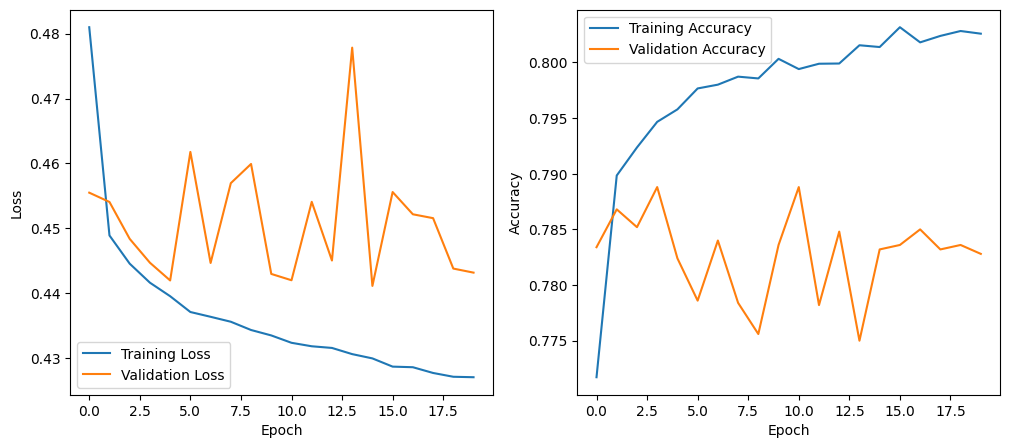

In [27]:
history_dnn2 = dnn2.fit(
    X_Train_All,
    y_Train,
    epochs=20,
    batch_size=256,
    validation_data=(X_Val_All, y_Val)
)

plot_history(history_dnn2)

Epoch 1/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7450 - loss: 0.5193 - val_accuracy: 0.7798 - val_loss: 0.4554
Epoch 2/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 882us/step - accuracy: 0.7927 - loss: 0.4468 - val_accuracy: 0.7872 - val_loss: 0.4459
Epoch 3/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7951 - loss: 0.4401 - val_accuracy: 0.7832 - val_loss: 0.4512
Epoch 4/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 923us/step - accuracy: 0.7932 - loss: 0.4440 - val_accuracy: 0.7818 - val_loss: 0.4428
Epoch 5/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 903us/step - accuracy: 0.7960 - loss: 0.4411 - val_accuracy: 0.7854 - val_loss: 0.4414
Epoch 6/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 882us/step - accuracy: 0.7923 - loss: 0.4448 - val_accuracy: 0.7850 - val_loss: 0.4448
Epoch 7/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 853us/step - accuracy: 0.7967 - loss: 0.4347 - val_accuracy: 0.7816 - val_loss: 0.4397
Epoch 8/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 828us/step - accuracy: 0.7966 - loss: 0.4388 - val_

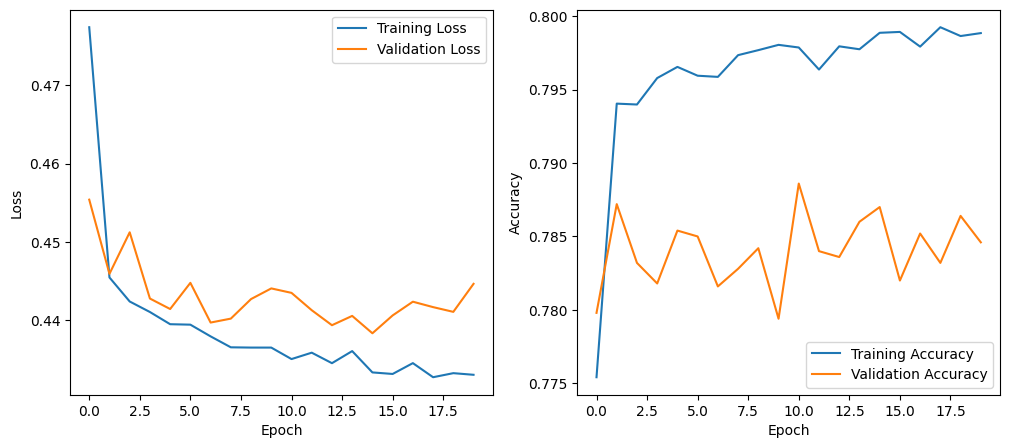

In [28]:
history_dnn3 = dnn3.fit(
    X_Train_All,
    y_Train,
    epochs=20,
    batch_size=256,
    validation_data=(X_Val_All, y_Val)
)

plot_history(history_dnn3)

In [29]:
from sklearn.metrics import roc_auc_score

models = [dnn1, dnn2, dnn3]
histories = [history_dnn1, history_dnn2, history_dnn3]

for i, (model, history) in enumerate(zip(models, histories), 1):
    predictions = model.predict(X_Test_All).ravel()
    auc = roc_auc_score(y_Test, predictions)
    val_accuracy = max(history.history["val_accuracy"])

    print(f"Model {i}")
    print(f"Best validation accuracy: {val_accuracy:.4f}")
    print(f"Test AUC: {auc:.4f}")
    print()

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 390us/step
Model 1
Best validation accuracy: 0.7876
Test AUC: 0.8674

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 409us/step
Model 2
Best validation accuracy: 0.7888
Test AUC: 0.8649

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 397us/step
Model 3
Best validation accuracy: 0.7886
Test AUC: 0.8654



## Exercise 4

Repeat Exercise 4 from Lab 8 (parts b and c), adding your best performing DNN as one of the models. Choose your best DNN using the validation sample, then compare on the test sample.

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 327us/step


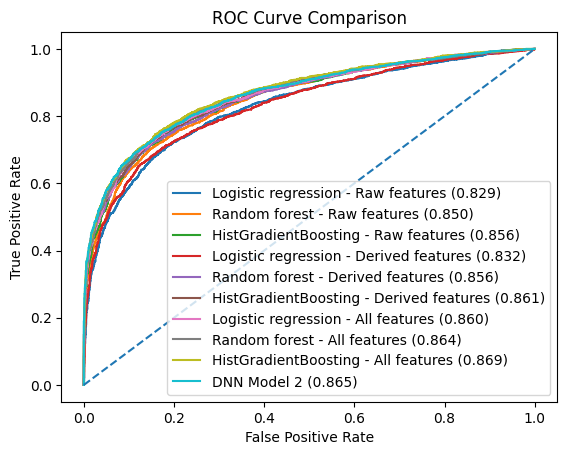

Logistic regression - Raw features AUC: 0.8294
Random forest - Raw features AUC: 0.85
HistGradientBoosting - Raw features AUC: 0.8561
Logistic regression - Derived features AUC: 0.8321
Random forest - Derived features AUC: 0.8558
HistGradientBoosting - Derived features AUC: 0.8606
Logistic regression - All features AUC: 0.8604
Random forest - All features AUC: 0.8642
HistGradientBoosting - All features AUC: 0.8688
DNN Model 2 - All features AUC: 0.8649


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

classifiers = {
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Random forest": RandomForestClassifier(
        n_estimators=50,
        max_depth=10,
        n_jobs=-1,
        random_state=42
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=100,
        random_state=42
    )
}

feature_sets = {
    "Raw features": (X_Train_Raw, X_Test_Raw),
    "Derived features": (X_Train_Features, X_Test_Features),
    "All features": (X_Train_All, X_Test_All)
}
results = {}

for name, (X_train, X_test) in feature_sets.items():

    for clf_name, clf in classifiers.items():

        clf.fit(X_train, y_Train)
        scores = clf.predict_proba(X_test)[:, 1]

        fpr, tpr, thresholds = roc_curve(y_Test, scores)
        score_auc = auc(fpr, tpr)

        results[clf_name + " - " + name] = score_auc

        plt.plot(fpr, tpr, label=f"{clf_name} - {name} ({score_auc:.3f})")

    if name == "All features":
        dnn_scores = dnn2.predict(X_Test_All).ravel()

        fpr, tpr, thresholds = roc_curve(y_Test, dnn_scores)
        dnn_auc = auc(fpr, tpr)

        results["DNN Model 2 - All features"] = dnn_auc

        plt.plot(fpr, tpr, label=f"DNN Model 2 ({dnn_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

for name, score in results.items():
    print(name, "AUC:", round(score, 4))

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 320us/step
Scenario 1
Best cut: 0.8473804397459274
Maximum significance: 1.7960161533727683
Scenario 2
Best cut: 0.8473804397459274
Maximum significance: 5.679501759112251
Scenario 3
Best cut: 0.8473804397459274
Maximum significance: 17.960161533727682
Scenario 4
Best cut: 0.8473804397459274
Maximum significance: 56.79501759112251


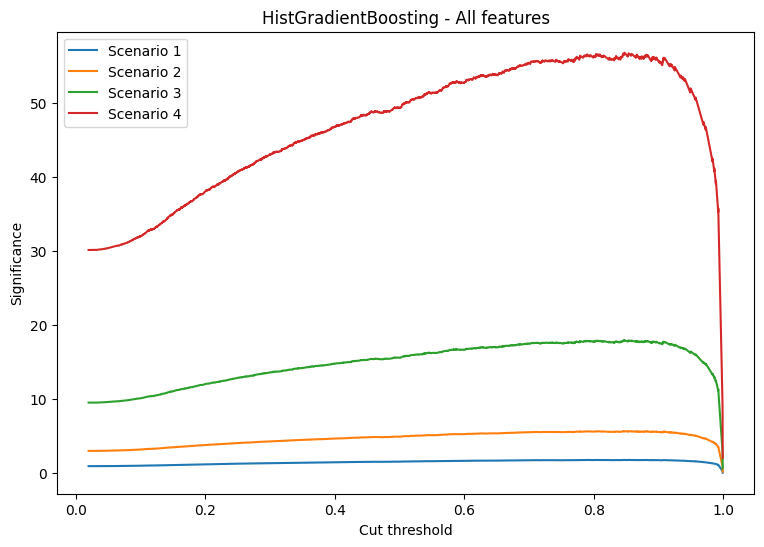

Scenario 1
Best cut: 0.81230336
Maximum significance: 1.8194228584844536
Scenario 2
Best cut: 0.81230336
Maximum significance: 5.753520259785082
Scenario 3
Best cut: 0.81230336
Maximum significance: 18.194228584844538
Scenario 4
Best cut: 0.81230336
Maximum significance: 57.53520259785082


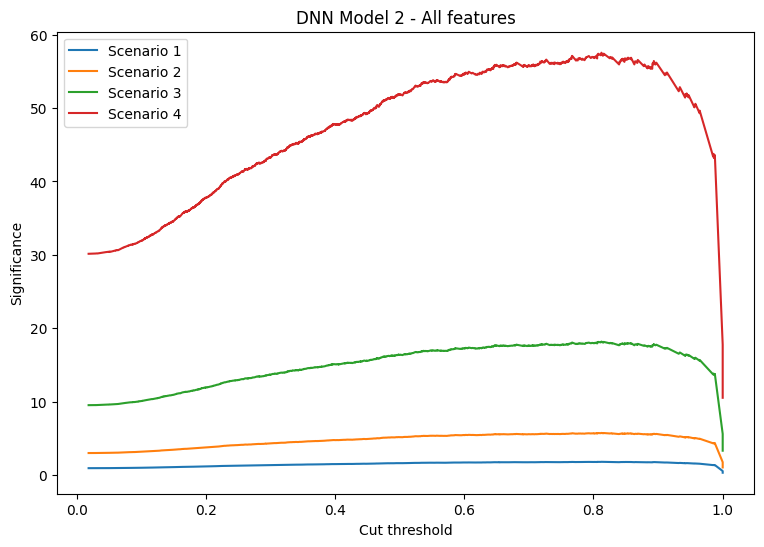

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_curve

boosting = HistGradientBoostingClassifier(max_iter=100, random_state=42)
boosting.fit(X_Train_All, y_Train)
boosting_scores = boosting.predict_proba(X_Test_All)[:, 1]
dnn_scores = dnn2.predict(X_Test_All).ravel()

def plot_significance(scores, title):
    fpr, tpr, thresholds = roc_curve(y_Test, scores)
    valid = np.isfinite(thresholds)
    fpr = fpr[valid]
    tpr = tpr[valid]
    thresholds = thresholds[valid]
    scenarios = [
        (10, 100, "Scenario 1"),
        (100, 1000, "Scenario 2"),
        (1000, 10000, "Scenario 3"),
        (10000, 100000, "Scenario 4")
    ]
    plt.figure(figsize=(9, 6))

    for NS, NB, name in scenarios:
        NS_selected = tpr * NS
        NB_selected = fpr * NB
        significance = np.divide(
            NS_selected,
            np.sqrt(NS_selected + NB_selected),
            out=np.zeros_like(NS_selected),
            where=(NS_selected + NB_selected) > 0
        )
        plt.plot(thresholds, significance, label=name)

        best_index = np.argmax(significance)
        print(name)
        print("Best cut:", thresholds[best_index])
        print("Maximum significance:", significance[best_index])

    plt.xlabel("Cut threshold")
    plt.ylabel("Significance")
    plt.title(title)
    plt.legend()
    plt.show()

plot_significance(boosting_scores, "HistGradientBoosting - All features")
plot_significance(dnn_scores, "DNN Model 2 - All features")